# 🧠 Hoja de Ruta del Quant
## 7 Conceptos para Dominar las Finanzas Cuantitativas con Python

---

**Autor:** Dr. Wellcome Peujio Jiotsop Foze  
**Institución:** [WP Wellness Academy](https://www.wpwellnessacademy.com)  
**Especialidad:** Economista Financiero y Energético  

---

> *"Las matemáticas son el lenguaje en el que Dios escribió el universo."*  
> — Galileo Galilei

Este notebook es la **hoja de ruta completa** para convertirte en analista cuantitativo (quant). Cada sección combina teoría, fórmulas matemáticas y código Python ejecutable aplicado a datos financieros reales.

### 📚 Recursos del Autor

| Recurso | Descripción | Enlace |
|---|---|---|
| 📘 **eBook Finanzas 5.0** | Guía de referencia: fundamentos a modelos avanzados | [Acceder →](https://www.wpwellnessacademy.com/finanzas-50-un-enfoque-moderno-basado-en-datos-y-python-ebook-digital) |
| 🎓 **Curso Profesional Python para Finanzas 5.0** | Programa completo con proyectos reales y acompañamiento del autor | [Inscribirse →](https://www.wpwellnessacademy.com/curso-profesional-python-para-finanzas-50) |

---

### 🗺️ Mapa del Notebook

| # | Concepto | Herramientas Python |
|---|---|---|
| 1 | Probabilidad y Estadística | `scipy.stats`, `numpy`, `yfinance` |
| 2 | Álgebra Lineal | `numpy`, `sklearn.decomposition.PCA` |
| 3 | Cálculo Estocástico | `numpy` (simulación Monte Carlo) |
| 4 | Optimización de Portafolios | `scipy.optimize`, `yfinance` |
| 5 | Python para Finanzas | `yfinance`, `pandas`, `numpy`, `scipy` |
| 6 | Econometría y Series de Tiempo | `statsmodels`, `arch` |
| 7 | Mercados y Microestructura | `yfinance`, `numpy`, `pandas` |

## ⚙️ Instalación de Dependencias

Ejecuta esta celda una sola vez para instalar todas las librerías necesarias.

In [1]:
# Instalar librerías necesarias (ejecutar solo una vez)
import subprocess, sys

paquetes = [
    'yfinance',
    'pandas',
    'numpy',
    'scipy',
    'matplotlib',
    'seaborn',
    'statsmodels',
    'scikit-learn',
    'arch'
]

for pkg in paquetes:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', pkg, '-q'])

print('✅ Todas las dependencias instaladas correctamente.')

✅ Todas las dependencias instaladas correctamente.


---
## 📊 Concepto 1: Probabilidad y Estadística
### La Base de Todo Modelo Cuantitativo

La probabilidad y la estadística son los cimientos sobre los que se construye cualquier modelo cuantitativo. Los retornos financieros reales exhiben **colas pesadas** (*fat tails*) y **asimetría negativa**, lo que significa que los eventos extremos ocurren con mayor frecuencia de lo que predice la distribución normal.

### Función de Densidad Normal

$$f(x) = \frac{1}{\sigma\sqrt{2\pi}} \cdot e^{-\frac{(x-\mu)^2}{2\sigma^2}}$$

### Regla Empírica (68 – 95 – 99.7)

| Rango | Probabilidad |
|---|---|
| $\mu \pm 1\sigma$ | 68.27% |
| $\mu \pm 2\sigma$ | 95.45% |
| $\mu \pm 3\sigma$ | 99.73% |

### Distribuciones Clave en Finanzas

| Distribución | Aplicación | Parámetros |
|---|---|---|
| Normal | Retornos diarios (aproximación) | μ, σ |
| Log-normal | Precios de activos (Black-Scholes) | μ, σ del log |
| t de Student | Retornos con colas pesadas | ν (grados de libertad) |
| Poisson | Eventos de crédito, defaults | λ (tasa de ocurrencia) |
| Pareto | Pérdidas extremas, VaR de cola | α (índice de cola) |

> 📖 **Fuente:** Hull, J. (2022). *Options, Futures and Other Derivatives* (11ª ed.). Pearson.

/tmp/ipykernel_6398/2110709750.py:9: FutureWarning: YF.download() has changed argument auto_adjust default to True
  sp500 = yf.download('^GSPC', start='2015-01-01', end='2024-12-31',


  ESTADÍSTICAS DE RETORNOS — S&P 500 (2015-2024)
  Observaciones:      2,514
  Media diaria:       0.000419
  Desv. estándar:     0.011272
  Asimetría:          -0.8108  (negativa = cola izquierda)
  Curtosis (exceso):  15.7508  (>0 = colas pesadas)

  Prueba Jarque-Bera:
    Estadístico JB:  26,151.33
    p-valor:         0.00e+00
    ¿Distribución normal? No ❌ (al 5%)


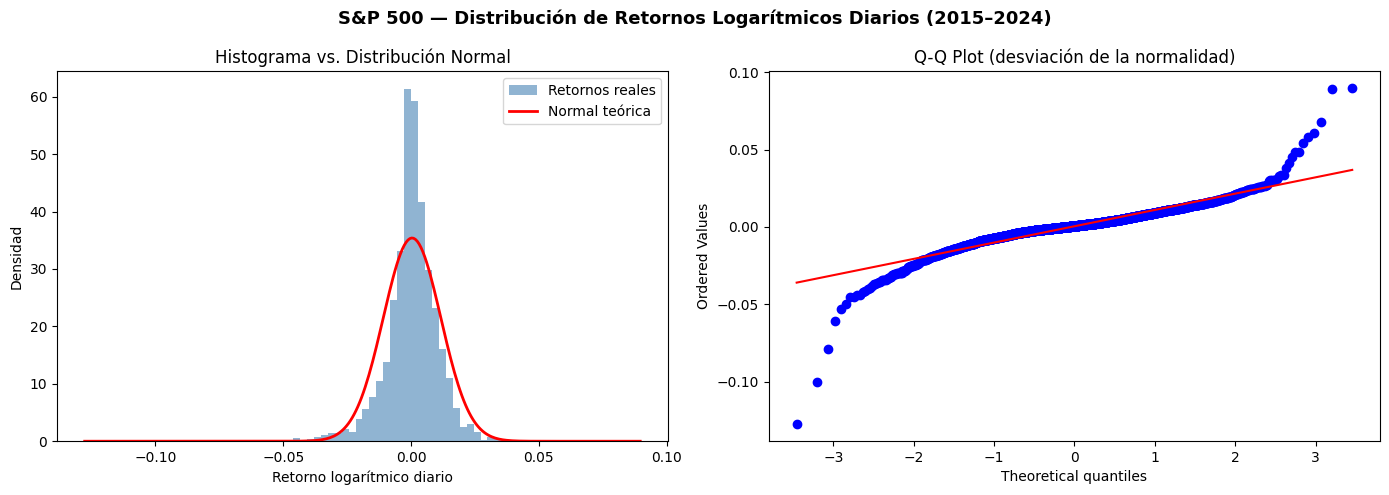


💡 Observa las colas pesadas en el histograma y la desviación en el Q-Q plot.


In [2]:
import numpy as np
import pandas as pd
import yfinance as yf
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from scipy import stats

# ── Descargar datos del S&P 500 ──────────────────────────────────────────────
sp500 = yf.download('^GSPC', start='2015-01-01', end='2024-12-31',
                    progress=False)['Close'].squeeze()
log_returns = np.log(sp500 / sp500.shift(1)).dropna()

# ── Estadísticas descriptivas ────────────────────────────────────────────────
print("=" * 50)
print("  ESTADÍSTICAS DE RETORNOS — S&P 500 (2015-2024)")
print("=" * 50)
print(f"  Observaciones:      {len(log_returns):,}")
print(f"  Media diaria:       {log_returns.mean():.6f}")
print(f"  Desv. estándar:     {log_returns.std():.6f}")
print(f"  Asimetría:          {log_returns.skew():.4f}  (negativa = cola izquierda)")
print(f"  Curtosis (exceso):  {log_returns.kurt():.4f}  (>0 = colas pesadas)")

# ── Prueba de normalidad Jarque-Bera ─────────────────────────────────────────
jb_stat, jb_pvalue = stats.jarque_bera(log_returns)
print(f"\n  Prueba Jarque-Bera:")
print(f"    Estadístico JB:  {jb_stat:,.2f}")
print(f"    p-valor:         {jb_pvalue:.2e}")
print(f"    ¿Distribución normal? {'No ❌' if jb_pvalue < 0.05 else 'Sí ✅'} (al 5%)")

# ── Visualización ────────────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('S&P 500 — Distribución de Retornos Logarítmicos Diarios (2015–2024)',
             fontsize=13, fontweight='bold')

# Histograma vs. Normal teórica
ax = axes[0]
x = np.linspace(log_returns.min(), log_returns.max(), 300)
ax.hist(log_returns, bins=80, density=True, alpha=0.6, color='steelblue',
        label='Retornos reales')
ax.plot(x, stats.norm.pdf(x, log_returns.mean(), log_returns.std()),
        'r-', lw=2, label='Normal teórica')
ax.set_xlabel('Retorno logarítmico diario')
ax.set_ylabel('Densidad')
ax.set_title('Histograma vs. Distribución Normal')
ax.legend()

# QQ-Plot
ax2 = axes[1]
stats.probplot(log_returns, dist='norm', plot=ax2)
ax2.set_title('Q-Q Plot (desviación de la normalidad)')
ax2.get_lines()[1].set_color('red')

plt.tight_layout()
plt.savefig('c1_probabilidad.png', dpi=150, bbox_inches='tight')
plt.show()
print("\n💡 Observa las colas pesadas en el histograma y la desviación en el Q-Q plot.")

---
## 🔢 Concepto 2: Álgebra Lineal
### El Motor de la Optimización de Portafolios

El álgebra lineal es el lenguaje matemático de la optimización de portafolios y el machine learning financiero. Las matrices, los vectores propios y la descomposición SVD son herramientas indispensables.

### Matriz de Covarianza

$$\Sigma = \frac{X^T \cdot X}{n - 1}$$

Los elementos **diagonales** son las varianzas individuales; los **fuera de la diagonal** son las covarianzas entre pares de activos.

### Análisis de Componentes Principales (PCA)

El PCA identifica los **factores latentes** que explican la mayor parte de la varianza del mercado. En la práctica, los primeros 3–5 componentes suelen explicar más del 80% de la varianza de un portafolio diversificado.

> 📖 **Fuente:** Strang, G. (2019). *Linear Algebra and Learning from Data*. Wellesley-Cambridge Press.

/tmp/ipykernel_6398/2608188445.py:12: FutureWarning: YF.download() has changed argument auto_adjust default to True
  data = yf.download(tickers, start='2020-01-01', end='2024-12-31',


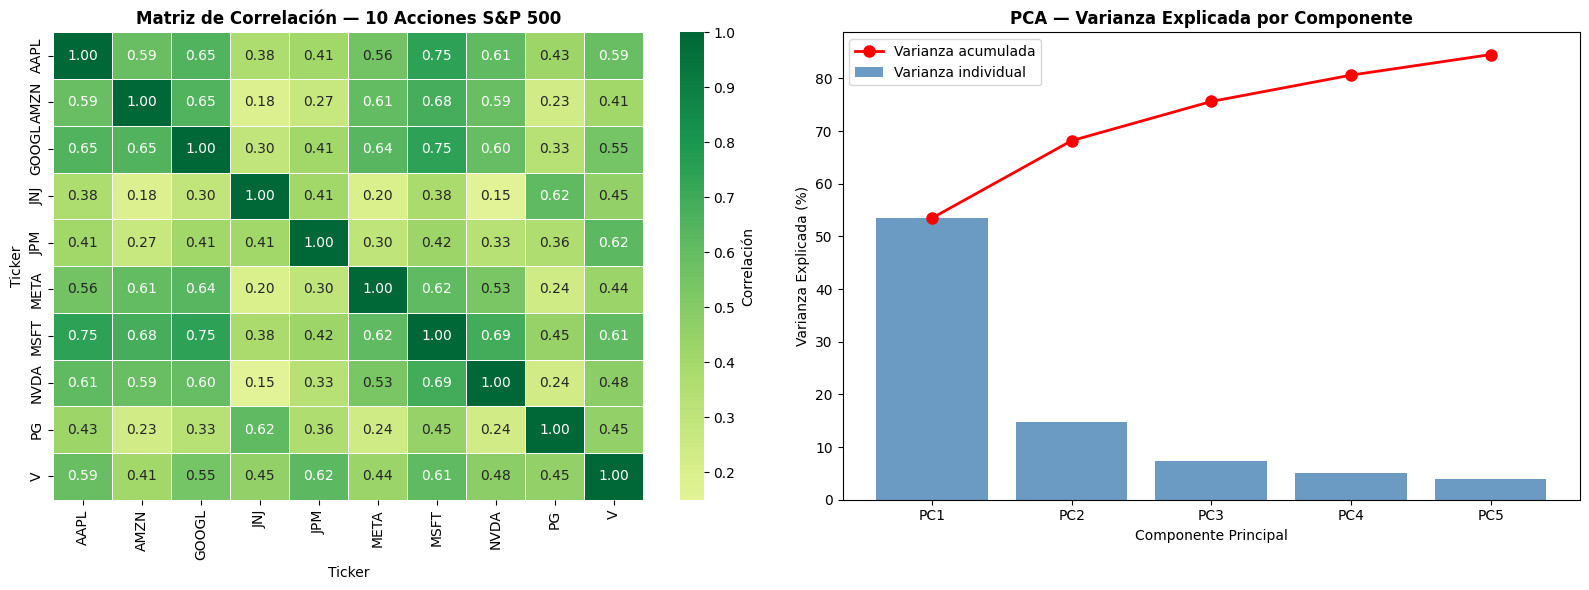

Varianza explicada por componente:
  PC1: 53.5%  (acumulada: 53.5%)
  PC2: 14.7%  (acumulada: 68.2%)
  PC3: 7.4%  (acumulada: 75.6%)
  PC4: 5.0%  (acumulada: 80.6%)
  PC5: 3.9%  (acumulada: 84.5%)


In [3]:
import numpy as np
import pandas as pd
import yfinance as yf
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

tickers = ['AAPL', 'MSFT', 'GOOGL', 'AMZN', 'META',
           'NVDA', 'JPM', 'JNJ', 'V', 'PG']

data = yf.download(tickers, start='2020-01-01', end='2024-12-31',
                   progress=False)['Close']
returns = np.log(data / data.shift(1)).dropna()

# ── Matriz de correlación ────────────────────────────────────────────────────
corr_matrix = returns.corr()

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Heatmap de correlaciones
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='RdYlGn',
            center=0, ax=axes[0], linewidths=0.5,
            cbar_kws={'label': 'Correlación'})
axes[0].set_title('Matriz de Correlación — 10 Acciones S&P 500', fontweight='bold')

# PCA — Varianza explicada
scaler = StandardScaler()
returns_scaled = scaler.fit_transform(returns)
pca = PCA(n_components=5)
pca.fit(returns_scaled)

var_exp = pca.explained_variance_ratio_ * 100
var_cum = np.cumsum(var_exp)

x_pos = range(1, 6)
axes[1].bar(x_pos, var_exp, color='steelblue', alpha=0.8, label='Varianza individual')
axes[1].plot(x_pos, var_cum, 'ro-', lw=2, ms=8, label='Varianza acumulada')
axes[1].set_xlabel('Componente Principal')
axes[1].set_ylabel('Varianza Explicada (%)')
axes[1].set_title('PCA — Varianza Explicada por Componente', fontweight='bold')
axes[1].legend()
axes[1].set_xticks(x_pos)
axes[1].set_xticklabels([f'PC{i}' for i in x_pos])

plt.tight_layout()
plt.savefig('c2_algebra_lineal.png', dpi=150, bbox_inches='tight')
plt.show()

print("Varianza explicada por componente:")
for i, (v, vc) in enumerate(zip(var_exp, var_cum), 1):
    print(f"  PC{i}: {v:.1f}%  (acumulada: {vc:.1f}%)")

---
## 🎲 Concepto 3: Cálculo Estocástico
### Modelando la Aleatoriedad del Mercado

El cálculo estocástico estudia los procesos aleatorios continuos en el tiempo. La aplicación más importante en finanzas es el **Movimiento Browniano Geométrico (GBM)**.

### Ecuación Diferencial Estocástica (SDE)

$$dS = \mu S \cdot dt + \sigma S \cdot dW_t$$

**Solución analítica:**

$$S(t) = S(0) \cdot \exp\left[\left(\mu - \frac{\sigma^2}{2}\right)t + \sigma W_t\right]$$

### Ecuación de Black-Scholes (Lema de Itô)

$$\frac{\partial V}{\partial t} + \frac{1}{2}\sigma^2 S^2 \frac{\partial^2 V}{\partial S^2} + rS\frac{\partial V}{\partial S} - rV = 0$$

> 📖 **Fuente:** Shreve, S.E. (2004). *Stochastic Calculus for Finance II*. Springer.

  SIMULACIÓN GBM — 1,000 TRAYECTORIAS (1 año)
  Precio inicial:          $100.00
  Precio esperado (teórico): $110.52
  Precio medio (simulado):   $110.47
  Mediana:                   $109.20
  Percentil  5%:             $78.09
  Percentil 95%:             $149.96
  Prob. de pérdida:          33.8%


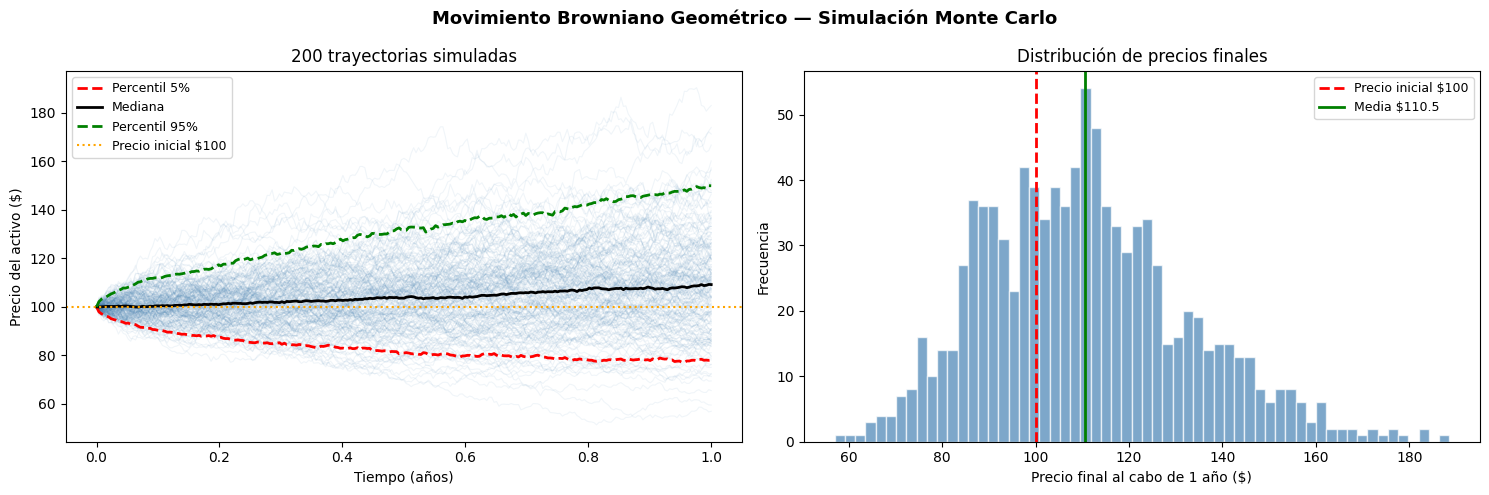

In [4]:
import numpy as np
import matplotlib.pyplot as plt

def simular_gbm(S0, mu, sigma, T, dt, n_paths, seed=42):
    """
    Simula trayectorias de Movimiento Browniano Geométrico.

    Parámetros
    ----------
    S0      : Precio inicial del activo
    mu      : Tasa de deriva anual (drift)
    sigma   : Volatilidad anual
    T       : Horizonte temporal en años
    dt      : Paso de tiempo (1/252 = diario)
    n_paths : Número de trayectorias a simular
    """
    np.random.seed(seed)
    n_steps = int(T / dt)
    t = np.linspace(0, T, n_steps + 1)

    # Incrementos Brownianos
    dW = np.random.normal(0, np.sqrt(dt), (n_paths, n_steps))

    # Solución exacta del GBM
    log_inc = (mu - 0.5 * sigma**2) * dt + sigma * dW
    log_S   = np.log(S0) + np.cumsum(log_inc, axis=1)
    S = np.exp(np.column_stack([np.full(n_paths, np.log(S0)), log_S]))

    return t, S

# ── Parámetros del modelo ────────────────────────────────────────────────────
S0, mu, sigma = 100, 0.10, 0.20
T, dt = 1.0, 1/252
n_paths = 1000

t, paths = simular_gbm(S0, mu, sigma, T, dt, n_paths)

# ── Estadísticas finales ─────────────────────────────────────────────────────
S_final = paths[:, -1]
print("=" * 50)
print("  SIMULACIÓN GBM — 1,000 TRAYECTORIAS (1 año)")
print("=" * 50)
print(f"  Precio inicial:          ${S0:.2f}")
print(f"  Precio esperado (teórico): ${S0 * np.exp(mu * T):.2f}")
print(f"  Precio medio (simulado):   ${S_final.mean():.2f}")
print(f"  Mediana:                   ${np.median(S_final):.2f}")
print(f"  Percentil  5%:             ${np.percentile(S_final,  5):.2f}")
print(f"  Percentil 95%:             ${np.percentile(S_final, 95):.2f}")
print(f"  Prob. de pérdida:          {(S_final < S0).mean()*100:.1f}%")

# ── Visualización ────────────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
fig.suptitle('Movimiento Browniano Geométrico — Simulación Monte Carlo',
             fontsize=13, fontweight='bold')

# Trayectorias
ax = axes[0]
for i in range(min(200, n_paths)):
    ax.plot(t, paths[i], alpha=0.08, color='steelblue', lw=0.8)
ax.plot(t, np.percentile(paths, 5,  axis=0), 'r--', lw=2, label='Percentil 5%')
ax.plot(t, np.percentile(paths, 50, axis=0), 'k-',  lw=2, label='Mediana')
ax.plot(t, np.percentile(paths, 95, axis=0), 'g--', lw=2, label='Percentil 95%')
ax.axhline(S0, color='orange', lw=1.5, linestyle=':', label=f'Precio inicial ${S0}')
ax.set_xlabel('Tiempo (años)')
ax.set_ylabel('Precio del activo ($)')
ax.set_title('200 trayectorias simuladas')
ax.legend(fontsize=9)

# Distribución final
ax2 = axes[1]
ax2.hist(S_final, bins=60, color='steelblue', alpha=0.7, edgecolor='white')
ax2.axvline(S0, color='red', lw=2, linestyle='--', label=f'Precio inicial ${S0}')
ax2.axvline(S_final.mean(), color='green', lw=2, label=f'Media ${S_final.mean():.1f}')
ax2.set_xlabel('Precio final al cabo de 1 año ($)')
ax2.set_ylabel('Frecuencia')
ax2.set_title('Distribución de precios finales')
ax2.legend(fontsize=9)

plt.tight_layout()
plt.savefig('c3_calculo_estocastico.png', dpi=150, bbox_inches='tight')
plt.show()

---
## 📐 Concepto 4: Optimización
### Construyendo Portafolios Eficientes — Teoría de Markowitz

La **Teoría Moderna de Portafolios (MPT)** de Harry Markowitz (1952) transformó la gestión de inversiones en un problema matemático formal.

### Problema de Optimización

$$\min_{\mathbf{w}} \quad \mathbf{w}^T \Sigma \mathbf{w}$$

$$\text{sujeto a:} \quad \mathbf{w}^T \boldsymbol{\mu} = \mu_p, \quad \sum_i w_i = 1, \quad w_i \geq 0$$

### Ratio de Sharpe

$$SR = \frac{R_p - R_f}{\sigma_p}$$

> 📖 **Fuente:** Markowitz, H. (1952). Portfolio Selection. *Journal of Finance*, 7(1), 77–91.

/tmp/ipykernel_6398/118266238.py:8: FutureWarning: YF.download() has changed argument auto_adjust default to True
  data = yf.download(tickers, start='2019-01-01', end='2024-12-31',


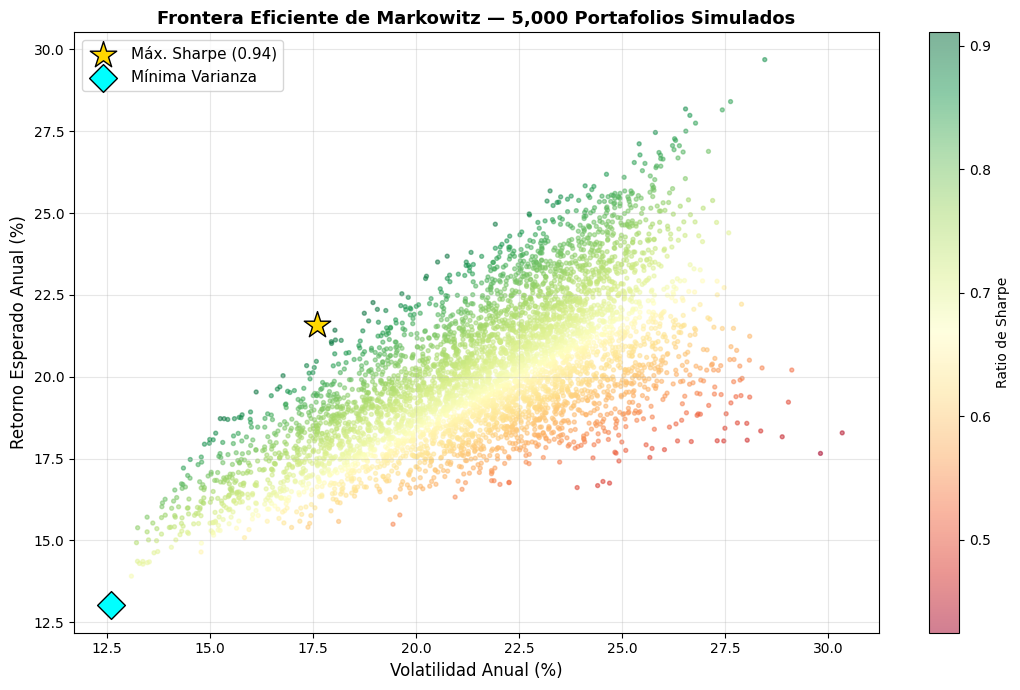


Portafolio de Máximo Ratio de Sharpe:
----------------------------------------
  AAPL  : 45.7%
  GOOGL : 45.0%
  JPM   : 5.5%
  GLD   : 3.8%

  Retorno esperado:  21.58%
  Volatilidad:       17.60%
  Ratio de Sharpe:   0.9417


In [5]:
import numpy as np
import pandas as pd
import yfinance as yf
import matplotlib.pyplot as plt
from scipy.optimize import minimize

tickers = ['AAPL', 'MSFT', 'GOOGL', 'AMZN', 'JPM', 'GLD', 'SPY']
data = yf.download(tickers, start='2019-01-01', end='2024-12-31',
                   progress=False)['Close']
returns = np.log(data / data.shift(1)).dropna()

mu  = returns.mean() * 252
cov = returns.cov() * 252
n   = len(tickers)
rf  = 0.05  # Tasa libre de riesgo

def portfolio_stats(w):
    ret = np.dot(w, mu)
    vol = np.sqrt(np.dot(w.T, np.dot(cov, w)))
    sharpe = (ret - rf) / vol
    return ret, vol, sharpe

constraints = {'type': 'eq', 'fun': lambda w: np.sum(w) - 1}
bounds = tuple((0, 1) for _ in range(n))
w0 = np.array([1/n] * n)

# Portafolio de Máximo Sharpe
res_sharpe = minimize(lambda w: -portfolio_stats(w)[2], w0,
                      method='SLSQP', bounds=bounds, constraints=constraints)

# Portafolio de Mínima Varianza
res_minvar = minimize(lambda w: portfolio_stats(w)[1], w0,
                      method='SLSQP', bounds=bounds, constraints=constraints)

# Frontera Eficiente (simulación Monte Carlo)
np.random.seed(42)
n_sim = 5000
sim_ret, sim_vol, sim_sharpe = [], [], []

for _ in range(n_sim):
    w = np.random.dirichlet(np.ones(n))
    r, v, s = portfolio_stats(w)
    sim_ret.append(r)
    sim_vol.append(v)
    sim_sharpe.append(s)

sim_ret    = np.array(sim_ret)
sim_vol    = np.array(sim_vol)
sim_sharpe = np.array(sim_sharpe)

# ── Visualización ────────────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(11, 7))

sc = ax.scatter(sim_vol * 100, sim_ret * 100, c=sim_sharpe,
                cmap='RdYlGn', alpha=0.5, s=8)
plt.colorbar(sc, ax=ax, label='Ratio de Sharpe')

# Portafolio Máximo Sharpe
r_s, v_s, sh_s = portfolio_stats(res_sharpe.x)
ax.scatter(v_s * 100, r_s * 100, marker='*', s=400, color='gold',
           zorder=5, edgecolors='black', label=f'Máx. Sharpe ({sh_s:.2f})')

# Portafolio Mínima Varianza
r_m, v_m, _ = portfolio_stats(res_minvar.x)
ax.scatter(v_m * 100, r_m * 100, marker='D', s=200, color='cyan',
           zorder=5, edgecolors='black', label='Mínima Varianza')

ax.set_xlabel('Volatilidad Anual (%)', fontsize=12)
ax.set_ylabel('Retorno Esperado Anual (%)', fontsize=12)
ax.set_title('Frontera Eficiente de Markowitz — 5,000 Portafolios Simulados',
             fontsize=13, fontweight='bold')
ax.legend(fontsize=11)
ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig('c4_optimizacion.png', dpi=150, bbox_inches='tight')
plt.show()

print("\nPortafolio de Máximo Ratio de Sharpe:")
print("-" * 40)
for t, w in zip(tickers, res_sharpe.x):
    if w > 0.01:
        print(f"  {t:6s}: {w*100:.1f}%")
print(f"\n  Retorno esperado:  {r_s*100:.2f}%")
print(f"  Volatilidad:       {v_s*100:.2f}%")
print(f"  Ratio de Sharpe:   {sh_s:.4f}")

---
## 🐍 Concepto 5: Programación en Python
### El Lenguaje Estándar del Quant Moderno

Python se ha consolidado como el lenguaje estándar de la industria cuantitativa, desplazando a MATLAB y R en la mayoría de las aplicaciones financieras.

### Stack Tecnológico del Quant

| Librería | Función Principal | Caso de Uso en Finanzas |
|---|---|---|
| **NumPy** | Álgebra lineal, arrays | Matrices de covarianza, Monte Carlo |
| **Pandas** | Manipulación de datos | Series de tiempo OHLCV |
| **SciPy** | Optimización, estadística | Frontera eficiente, pruebas |
| **Matplotlib / Plotly** | Visualización | Gráficas de precios, distribuciones |
| **Scikit-learn** | Machine learning | Señales de trading, clustering |
| **yfinance** | Datos financieros gratuitos | Precios históricos en segundos |
| **QuantLib** | Pricing de derivados | Opciones, bonos, swaps |
| **Backtrader** | Backtesting | Simulación de estrategias |

> 💡 El **[Curso Profesional Python para Finanzas 5.0](https://www.wpwellnessacademy.com/curso-profesional-python-para-finanzas-50)** del Dr. Wellcome Peujio cubre cada una de estas librerías con proyectos aplicados a datos reales de mercado.

> 📖 **Fuente:** McKinney, W. (2022). *Python for Data Analysis* (3ª ed.). O'Reilly Media.

In [6]:
import yfinance as yf
import numpy as np
import pandas as pd
from scipy import stats
import matplotlib.pyplot as plt

def pipeline_analisis_financiero(ticker: str, start: str, end: str) -> dict:
    """
    Pipeline completo de análisis cuantitativo para un activo financiero.
    Retorna un diccionario con las métricas clave de riesgo-retorno.
    """
    data     = yf.download(ticker, start=start, end=end, progress=False)
    precios  = data['Close'].squeeze()
    retornos = np.log(precios / precios.shift(1)).dropna()

    mu_anual    = retornos.mean() * 252
    sigma_anual = retornos.std() * np.sqrt(252)
    sharpe      = mu_anual / sigma_anual
    var_95      = np.percentile(retornos, 5)

    precio_acum = (1 + retornos).cumprod()
    drawdown    = (precio_acum - precio_acum.cummax()) / precio_acum.cummax()
    max_dd      = drawdown.min()
    cagr        = precio_acum.iloc[-1] ** (252 / len(retornos)) - 1
    calmar      = cagr / abs(max_dd)

    _, p_normal = stats.jarque_bera(retornos)

    return {
        'Ticker':              ticker,
        'CAGR':                f"{cagr*100:.2f}%",
        'Volatilidad Anual':   f"{sigma_anual*100:.2f}%",
        'Ratio de Sharpe':     f"{sharpe:.4f}",
        'VaR 95% (diario)':    f"{var_95*100:.2f}%",
        'Max Drawdown':        f"{max_dd*100:.2f}%",
        'Calmar Ratio':        f"{calmar:.4f}",
        'Distribución Normal': 'No ❌' if p_normal < 0.05 else 'Sí ✅'
    }

# ── Análisis de múltiples activos ────────────────────────────────────────────
activos = ['AAPL', 'MSFT', 'SPY', 'GLD', 'BTC-USD']
resultados = [pipeline_analisis_financiero(a, '2020-01-01', '2024-12-31')
              for a in activos]

df_resultados = pd.DataFrame(resultados).set_index('Ticker')
print("\n📊 ANÁLISIS COMPARATIVO DE ACTIVOS (2020–2024)")
print("=" * 65)
print(df_resultados.to_string())

/tmp/ipykernel_6398/1591910290.py:12: FutureWarning: YF.download() has changed argument auto_adjust default to True
  data     = yf.download(ticker, start=start, end=end, progress=False)
/tmp/ipykernel_6398/1591910290.py:12: FutureWarning: YF.download() has changed argument auto_adjust default to True
  data     = yf.download(ticker, start=start, end=end, progress=False)
/tmp/ipykernel_6398/1591910290.py:12: FutureWarning: YF.download() has changed argument auto_adjust default to True
  data     = yf.download(ticker, start=start, end=end, progress=False)
/tmp/ipykernel_6398/1591910290.py:12: FutureWarning: YF.download() has changed argument auto_adjust default to True
  data     = yf.download(ticker, start=start, end=end, progress=False)
/tmp/ipykernel_6398/1591910290.py:12: FutureWarning: YF.download() has changed argument auto_adjust default to True
  data     = yf.download(ticker, start=start, end=end, progress=False)



📊 ANÁLISIS COMPARATIVO DE ACTIVOS (2020–2024)
           CAGR Volatilidad Anual Ratio de Sharpe VaR 95% (diario) Max Drawdown Calmar Ratio Distribución Normal
Ticker                                                                                                          
AAPL     22.02%            31.66%          0.7873           -3.06%      -35.18%       0.6260                No ❌
MSFT     17.03%            30.53%          0.6684           -2.90%      -40.61%       0.4193                No ❌
SPY      11.84%            21.09%          0.6367           -1.95%      -35.75%       0.3311                No ❌
GLD       9.52%            15.55%          0.6630           -1.60%      -23.89%       0.3986                No ❌
BTC-USD  22.01%            54.11%          0.6519           -5.14%      -83.72%       0.2629                No ❌


---
## 📈 Concepto 6: Econometría y Series de Tiempo
### Capturando la Dinámica Temporal del Mercado

Los mercados financieros generan series de tiempo con características particulares: autocorrelación, heterocedasticidad y **agrupación de volatilidad** (*volatility clustering*).

### Modelo ARIMA(p,d,q)

$$y_t = c + \phi_1 y_{t-1} + \cdots + \phi_p y_{t-p} + \theta_1 \varepsilon_{t-1} + \cdots + \theta_q \varepsilon_{t-q} + \varepsilon_t$$

### Modelo GARCH(1,1) — Varianza Condicional

$$\sigma_t^2 = \omega + \alpha \varepsilon_{t-1}^2 + \beta \sigma_{t-1}^2$$

La **persistencia** de la volatilidad se mide como $\alpha + \beta$. Si $\alpha + \beta \approx 1$, los shocks de volatilidad son muy persistentes.

> 📖 **Fuente:** Tsay, R.S. (2010). *Analysis of Financial Time Series* (3ª ed.). Wiley.  
> 📖 **Fuente:** Bollerslev, T. (1986). Generalized Autoregressive Conditional Heteroskedasticity. *Journal of Econometrics*, 31(3), 307–327.

/tmp/ipykernel_6398/1599005701.py:9: FutureWarning: YF.download() has changed argument auto_adjust default to True
  data     = yf.download('SPY', start='2018-01-01', end='2024-12-31', progress=False)['Close']


Prueba Dickey-Fuller Aumentada (ADF):
  Estadístico ADF:  -12.9320
  p-valor:          0.000000
  ¿Estacionaria?    Sí ✅ (al 5%)

Modelo GARCH(1,1) — SPY (2018–2024):
  omega (ω):          0.032340
  alpha (α):          0.1732
  beta  (β):          0.8142
  Persistencia (α+β): 0.9875
  Volatilidad condicional actual: 17.28% anual


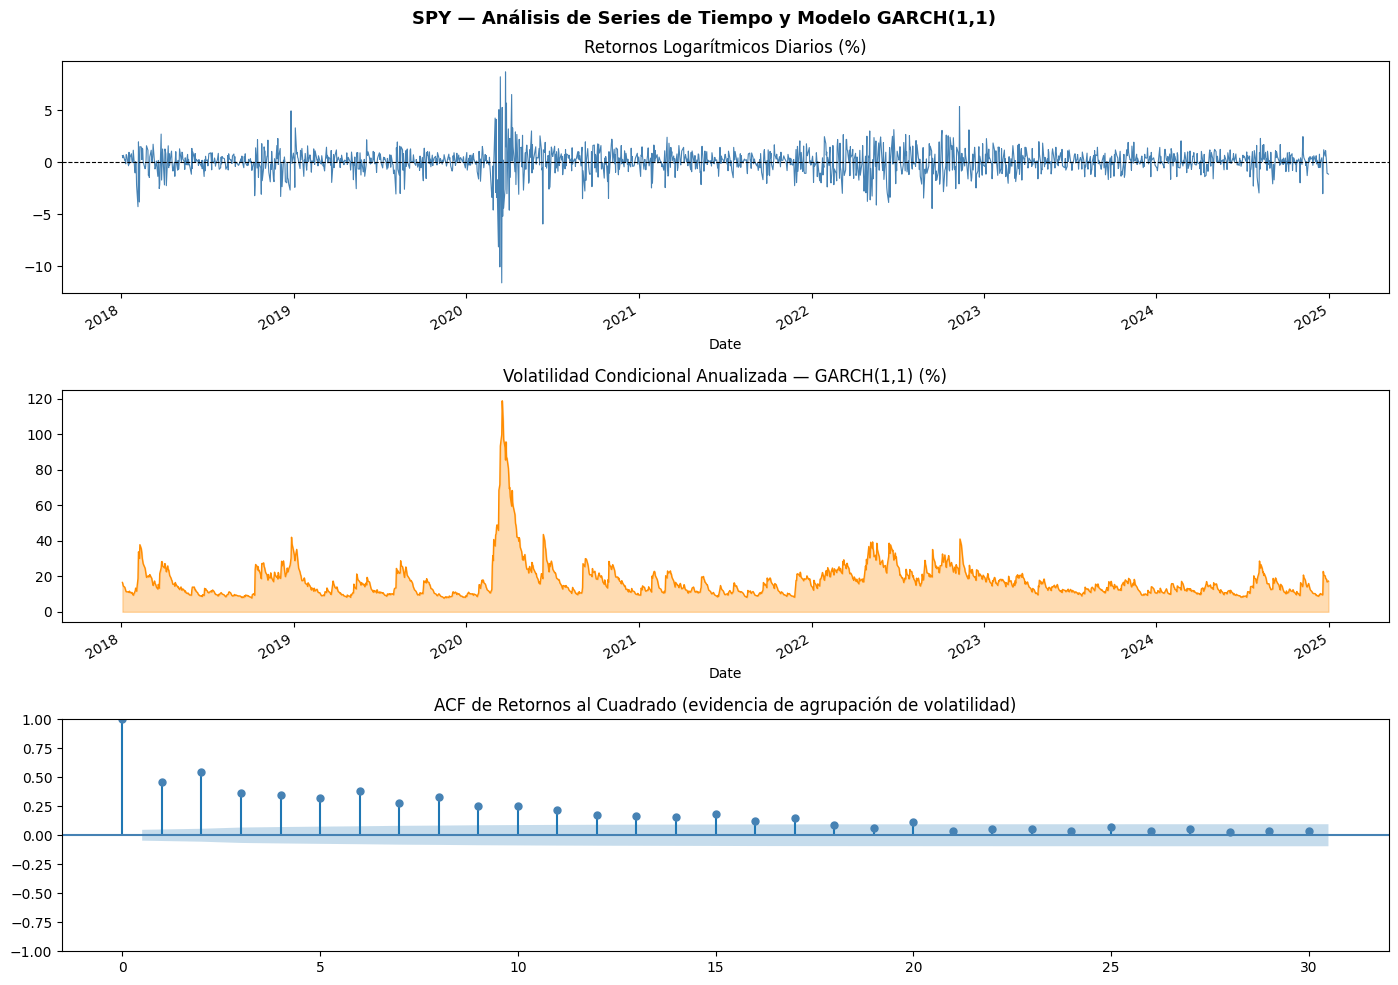

In [7]:
import numpy as np
import pandas as pd
import yfinance as yf
import matplotlib.pyplot as plt
from statsmodels.tsa.stattools import adfuller
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from arch import arch_model

data     = yf.download('SPY', start='2018-01-01', end='2024-12-31', progress=False)['Close']
retornos = np.log(data / data.shift(1)).dropna().squeeze() * 100  # En porcentaje

# ── Prueba de estacionariedad (ADF) ─────────────────────────────────────────
adf_stat, adf_p, _, _, crit, _ = adfuller(retornos)
print("Prueba Dickey-Fuller Aumentada (ADF):")
print(f"  Estadístico ADF:  {adf_stat:.4f}")
print(f"  p-valor:          {adf_p:.6f}")
print(f"  ¿Estacionaria?    {'Sí ✅' if adf_p < 0.05 else 'No ❌'} (al 5%)")

# ── Modelo GARCH(1,1) ────────────────────────────────────────────────────────
modelo_garch  = arch_model(retornos, vol='Garch', p=1, q=1, dist='t')
res_garch     = modelo_garch.fit(disp='off')

omega = res_garch.params['omega']
alpha = res_garch.params['alpha[1]']
beta  = res_garch.params['beta[1]']

print(f"\nModelo GARCH(1,1) — SPY (2018–2024):")
print(f"  omega (ω):          {omega:.6f}")
print(f"  alpha (α):          {alpha:.4f}")
print(f"  beta  (β):          {beta:.4f}")
print(f"  Persistencia (α+β): {alpha + beta:.4f}")

vol_cond = res_garch.conditional_volatility * np.sqrt(252)
print(f"  Volatilidad condicional actual: {vol_cond.iloc[-1]:.2f}% anual")

# ── Visualización ────────────────────────────────────────────────────────────
fig, axes = plt.subplots(3, 1, figsize=(14, 10))
fig.suptitle('SPY — Análisis de Series de Tiempo y Modelo GARCH(1,1)',
             fontsize=13, fontweight='bold')

retornos.plot(ax=axes[0], color='steelblue', lw=0.8)
axes[0].set_title('Retornos Logarítmicos Diarios (%)')
axes[0].axhline(0, color='black', lw=0.8, linestyle='--')

vol_cond.plot(ax=axes[1], color='darkorange', lw=1)
axes[1].set_title('Volatilidad Condicional Anualizada — GARCH(1,1) (%)')
axes[1].fill_between(vol_cond.index, vol_cond, alpha=0.3, color='darkorange')

plot_acf(retornos**2, lags=30, ax=axes[2], color='steelblue')
axes[2].set_title('ACF de Retornos al Cuadrado (evidencia de agrupación de volatilidad)')

plt.tight_layout()
plt.savefig('c6_econometria.png', dpi=150, bbox_inches='tight')
plt.show()

---
## 🏛️ Concepto 7: Mercados Financieros y Microestructura
### Entendiendo el Campo de Juego del Quant

Comprender la **microestructura de los mercados** —spreads, liquidez, impacto de precio y ejecución— es fundamental para que las estrategias cuantitativas sean rentables en la práctica.

### Spread Bid-Ask

$$\text{Spread} = P_{\text{ask}} - P_{\text{bid}}$$

### Métricas de Performance

| Métrica | Fórmula | Interpretación |
|---|---|---|
| **Ratio de Sharpe** | $(R_p - R_f) / \sigma_p$ | Retorno ajustado por riesgo total |
| **Ratio de Sortino** | $(R_p - R_f) / \sigma_{\text{down}}$ | Penaliza solo la volatilidad negativa |
| **Maximum Drawdown** | $(\text{peak} - \text{trough}) / \text{peak}$ | Peor pérdida desde un máximo |
| **Calmar Ratio** | $\text{CAGR} / |\text{Max DD}|$ | Retorno vs. peor pérdida histórica |
| **CVaR 95%** | $E[R \mid R \leq \text{VaR}_{95}]$ | Pérdida esperada en el peor 5% |

> 📖 **Fuente:** Harris, L. (2003). *Trading and Exchanges: Market Microstructure for Practitioners*. Oxford University Press.

/tmp/ipykernel_6398/3524908958.py:48: FutureWarning: YF.download() has changed argument auto_adjust default to True
  data     = yf.download(ticker, start='2020-01-01', end='2024-12-31', progress=False)['Close']
/tmp/ipykernel_6398/3524908958.py:48: FutureWarning: YF.download() has changed argument auto_adjust default to True
  data     = yf.download(ticker, start='2020-01-01', end='2024-12-31', progress=False)['Close']
/tmp/ipykernel_6398/3524908958.py:48: FutureWarning: YF.download() has changed argument auto_adjust default to True
  data     = yf.download(ticker, start='2020-01-01', end='2024-12-31', progress=False)['Close']


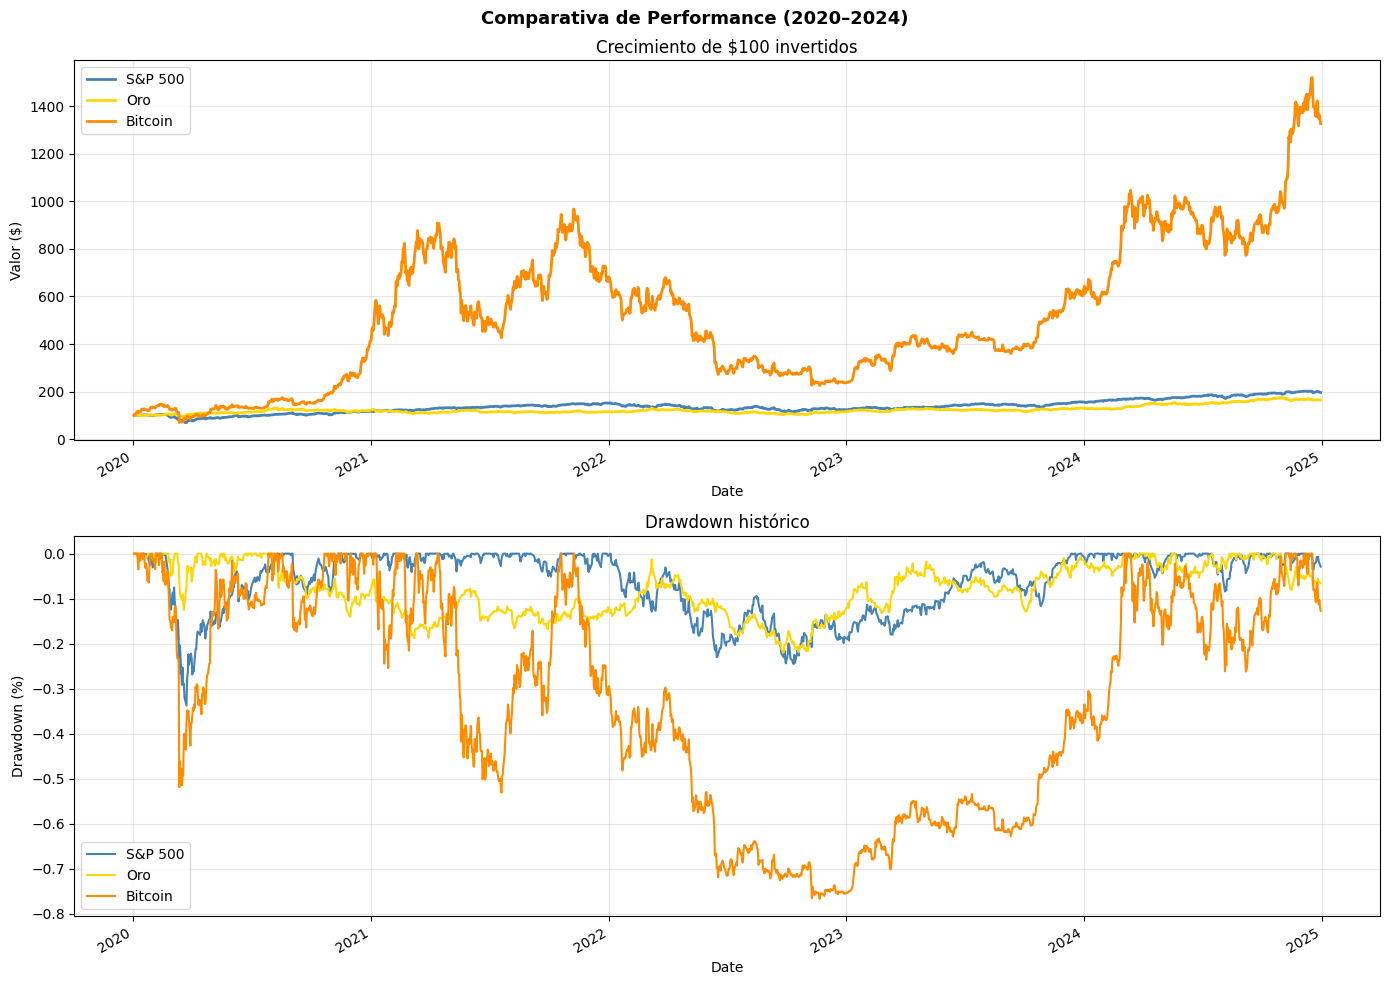


📊 TABLA COMPARATIVA DE MÉTRICAS DE PERFORMANCE (2020–2024)
        Retorno Anual (CAGR) Volatilidad Anual Ratio de Sharpe Ratio de Sortino Maximum Drawdown Calmar Ratio VaR 95% (diario) CVaR 95% (diario)
S&P 500               14.37%            21.00%          0.5127           0.5473          -33.72%       0.4263           -1.93%            -3.20%
Oro                   10.86%            15.53%          0.4275           0.5242          -22.00%       0.4935           -1.59%            -2.28%
Bitcoin               42.30%            53.27%          0.8424           0.9383          -76.63%       0.5519           -5.01%            -7.52%


In [8]:
import numpy as np
import pandas as pd
import yfinance as yf
import matplotlib.pyplot as plt

def calcular_metricas_performance(retornos: pd.Series, rf_anual: float = 0.05) -> dict:
    """
    Calcula las métricas de performance estándar de la industria.
    """
    rf_diario    = (1 + rf_anual) ** (1/252) - 1
    exceso       = retornos - rf_diario
    vol_anual    = retornos.std() * np.sqrt(252)
    sharpe       = exceso.mean() / exceso.std() * np.sqrt(252)

    vol_downside = retornos[retornos < rf_diario].std() * np.sqrt(252)
    riqueza      = (1 + retornos).cumprod()
    cagr         = riqueza.iloc[-1] ** (252 / len(retornos)) - 1
    sortino      = (cagr - rf_anual) / vol_downside

    drawdown     = (riqueza - riqueza.cummax()) / riqueza.cummax()
    max_dd       = drawdown.min()
    calmar       = cagr / abs(max_dd)

    var_95       = np.percentile(retornos, 5)
    cvar_95      = retornos[retornos <= var_95].mean()

    return {
        'Retorno Anual (CAGR)':  cagr,
        'Volatilidad Anual':     vol_anual,
        'Ratio de Sharpe':       sharpe,
        'Ratio de Sortino':      sortino,
        'Maximum Drawdown':      max_dd,
        'Calmar Ratio':          calmar,
        'VaR 95% (diario)':      var_95,
        'CVaR 95% (diario)':     cvar_95
    }, riqueza, drawdown

# ── Comparar tres activos ────────────────────────────────────────────────────
activos_comp = {'SPY': 'S&P 500', 'GLD': 'Oro', 'BTC-USD': 'Bitcoin'}
colores      = {'SPY': 'steelblue', 'GLD': 'gold', 'BTC-USD': 'darkorange'}

fig, axes = plt.subplots(2, 1, figsize=(14, 10))
fig.suptitle('Comparativa de Performance (2020–2024)', fontsize=13, fontweight='bold')

tabla_metricas = {}

for ticker, nombre in activos_comp.items():
    data     = yf.download(ticker, start='2020-01-01', end='2024-12-31', progress=False)['Close']
    retornos = data.pct_change().dropna().squeeze()
    metricas, riqueza, drawdown = calcular_metricas_performance(retornos)
    tabla_metricas[nombre] = metricas

    riqueza_norm = riqueza / riqueza.iloc[0] * 100
    riqueza_norm.plot(ax=axes[0], label=nombre, color=colores[ticker], lw=2)
    drawdown.plot(ax=axes[1], label=nombre, color=colores[ticker], lw=1.5)

axes[0].set_title('Crecimiento de $100 invertidos')
axes[0].set_ylabel('Valor ($)')
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].set_title('Drawdown histórico')
axes[1].set_ylabel('Drawdown (%)')
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig('c7_microestructura.png', dpi=150, bbox_inches='tight')
plt.show()

# Tabla comparativa
df_tabla = pd.DataFrame(tabla_metricas).T
df_fmt   = df_tabla.copy()
for col in ['Retorno Anual (CAGR)', 'Volatilidad Anual', 'Maximum Drawdown',
            'VaR 95% (diario)', 'CVaR 95% (diario)']:
    df_fmt[col] = df_tabla[col].apply(lambda x: f"{x*100:.2f}%")
for col in ['Ratio de Sharpe', 'Ratio de Sortino', 'Calmar Ratio']:
    df_fmt[col] = df_tabla[col].apply(lambda x: f"{x:.4f}")

print("\n📊 TABLA COMPARATIVA DE MÉTRICAS DE PERFORMANCE (2020–2024)")
print("=" * 75)
print(df_fmt.to_string())

---
## 🗓️ Hoja de Ruta Práctica: 16 Semanas hacia el Dominio Quant

| Semana | Enfoque | Proyecto Práctico |
|---|---|---|
| 1–2 | Probabilidad y Estadística | Analizar distribución de retornos del S&P 500 |
| 3–4 | Álgebra Lineal + PCA | Construir mapa de correlaciones de 20 acciones |
| 5–6 | Cálculo Estocástico | Simular 10,000 trayectorias con GBM |
| 7–8 | Optimización | Construir frontera eficiente con 10 activos |
| 9–10 | Python avanzado | Pipeline completo de análisis cuantitativo |
| 11–12 | Econometría | Modelo GARCH para volatilidad del Bitcoin |
| 13–14 | Microestructura | Backtest de estrategia de momentum simple |
| 15–16 | Integración final | Sistema completo: datos → modelo → backtest → métricas |

> 🚀 **Acelera tu aprendizaje:** El **[Curso Profesional Python para Finanzas 5.0](https://www.wpwellnessacademy.com/curso-profesional-python-para-finanzas-50)** está estructurado exactamente siguiendo esta hoja de ruta, con proyectos guiados, código descargable y el acompañamiento directo del **Dr. Wellcome Peujio Jiotsop Foze**.

---

## 📚 Recursos del Dr. Wellcome Peujio para Continuar tu Formación

### 📘 [Finanzas 5.0 — Un Enfoque Moderno Basado en Datos y Python (eBook Digital)](https://www.wpwellnessacademy.com/finanzas-50-un-enfoque-moderno-basado-en-datos-y-python-ebook-digital)
El libro de referencia que cubre desde los fundamentos de Python hasta los modelos cuantitativos más avanzados. Ideal para tener siempre a mano como guía de consulta durante tu formación.

### 🎓 [Curso Profesional: Python para Finanzas 5.0](https://www.wpwellnessacademy.com/curso-profesional-python-para-finanzas-50)
El programa formativo completo con proyectos reales, código funcional y acompañamiento del autor. La forma más eficiente de dominar los 7 conceptos de esta guía en tiempo récord.

---

## 📖 Referencias Académicas

1. Hull, J. (2022). *Options, Futures and Other Derivatives* (11ª ed.). Pearson.
2. Bureau of Labor Statistics. (2024). *Financial Analysts*. Occupational Outlook Handbook. https://www.bls.gov/ooh/business-and-financial/financial-analysts.htm
3. Fabozzi, F.J., Focardi, S.M., & Rachev, S.T. (2010). *Probability and Statistics for Finance*. Wiley.
4. Fama, E.F. (1965). The Behavior of Stock-Market Prices. *Journal of Business*, 38(1), 34–105.
5. Strang, G. (2019). *Linear Algebra and Learning from Data*. Wellesley-Cambridge Press.
6. Shreve, S.E. (2004). *Stochastic Calculus for Finance II: Continuous-Time Models*. Springer.
7. Black, F., & Scholes, M. (1973). The Pricing of Options and Corporate Liabilities. *Journal of Political Economy*, 81(3), 637–654.
8. Markowitz, H. (1952). Portfolio Selection. *Journal of Finance*, 7(1), 77–91.
9. McKinney, W. (2022). *Python for Data Analysis* (3ª ed.). O'Reilly Media.
10. Tsay, R.S. (2010). *Analysis of Financial Time Series* (3ª ed.). Wiley.
11. Bollerslev, T. (1986). Generalized Autoregressive Conditional Heteroskedasticity. *Journal of Econometrics*, 31(3), 307–327.
12. Harris, L. (2003). *Trading and Exchanges: Market Microstructure for Practitioners*. Oxford University Press.
13. Amihud, Y., & Mendelson, H. (1986). Asset Pricing and the Bid-Ask Spread. *Journal of Financial Economics*, 17(2), 223–249.

---

*© WP Wellness Academy — Dr. Wellcome Peujio Jiotsop Foze, Economista Financiero y Energético*  
*Este notebook es de carácter educativo y no constituye asesoramiento financiero ni de inversión.*